## Assignment no 19


## Amazon Product Review Sentiment Analysis--NLP

Step 1: Install required libraries

In [1]:
# Run this cell only if the required libraries are not installed

%pip install pandas numpy matplotlib seaborn scikit-learn wordcloud joblib

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: pandas in c:\users\yashr\anaconda3\lib\site-packages (2.2.2)
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
    --------------------------------------- 0.3/15.5 MB ? eta -:--:--
    --------------------------------------- 0.3/15.5 MB ? eta -:--:--
   - -------------------------------------- 0.5/15.5 MB 645.7 kB/s eta 0:00:24
   - -------------------------------------- 0.5/15.5 MB 645.7 kB/s eta 0:00:24
   -- ------------------------------------- 0.8/15.5 MB 729.2 kB/s eta 0:00:21
   -- ------------------------------------- 1.0/15.5 MB 762.8 kB/s eta 0:00:19
   -- ------------------------------------- 1.0/15.5 MB 762.8 kB/s eta 0:00:19
   --- ------------------------------------ 1.3/15.5 MB 721.7 kB/s eta 0:00:20
   --- ------------------------------------ 1.3/15.5 MB 721.7 kB/s eta 0:00:20
   ---- --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 7.36.2 which is incompatible.


Step 2: Import libraries

In [2]:
# Data handling
import pandas as pd
import numpy as np
import re
import string
import warnings

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
from wordcloud import WordCloud
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Save model
import joblib

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


Step 3: Load dataset

In [3]:
# Load Amazon reviews dataset
df = pd.read_csv("amazonreviews.tsv", sep="\t")

# Display first five records
display(df.head())

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


Step 4: Understand dataset

In [4]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nDataset Description:")
display(df.describe(include="all"))

# Check data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (10000, 2)

Column Names:
Index(['label', 'review'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   10000 non-null  object
 1   review  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB

Dataset Description:


,label,review
count,10000,10000
unique,2,10000
top,neg,Stuning even for the non-gamer: This sound tra...
freq,5097,1



Data Types:
label     object
review    object
dtype: object


Step 5: Check missing values

In [5]:
# Count missing values
print("Missing Values:")
print(df.isnull().sum())

# Missing value percentage
print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df)) * 100)

Missing Values:
label     0
review    0
dtype: int64

Missing Value Percentage:
label     0.0
review    0.0
dtype: float64


Step 6: Check duplicate records

In [6]:
# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate Rows: 0
Shape after removing duplicates: (10000, 2)


Step 7: Handle missing values

In [7]:
# Remove rows with missing labels or reviews
df = df.dropna(subset=["label", "review"])

# Remove empty reviews
df["review"] = df["review"].astype(str).str.strip()

df = df[df["review"] != ""]

# Reset index
df.reset_index(drop=True, inplace=True)

print("Shape after handling missing values:", df.shape)

display(df.head())

Shape after handling missing values: (10000, 2)


,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


Step 8: Check target variable

In [8]:
# Check unique sentiment labels
print("Unique Labels:", df["label"].unique())

# Count each sentiment
print("\nSentiment Counts:")
print(df["label"].value_counts())

# Check class distribution percentage
print("\nSentiment Percentage:")
print(df["label"].value_counts(normalize=True) * 100)

Unique Labels: ['pos' 'neg']

Sentiment Counts:
label
neg    5097
pos    4903
Name: count, dtype: int64

Sentiment Percentage:
label
neg    50.97
pos    49.03
Name: proportion, dtype: float64


Step 9: Sentiment distribution visualization

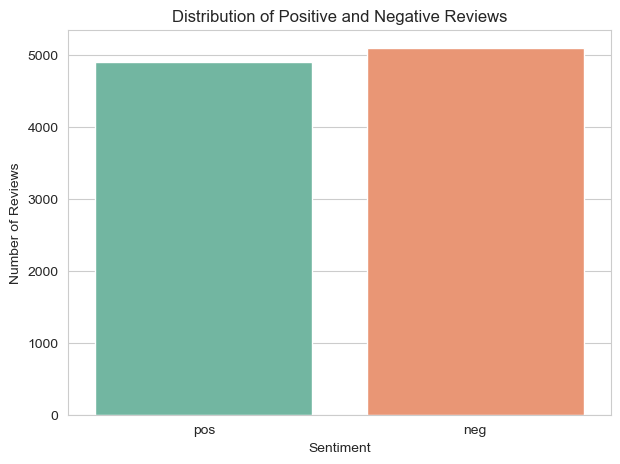

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=["pos", "neg"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

Step 10: Pie chart of sentiment distribution

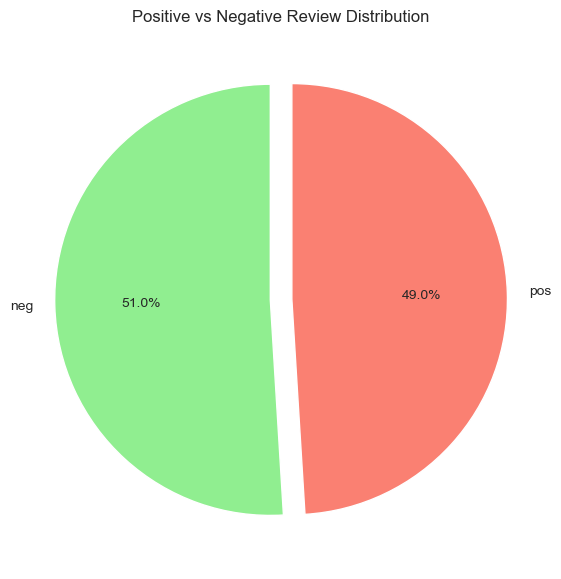

In [10]:
sentiment_counts = df["label"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["lightgreen", "salmon"],
    explode=[0.05, 0.05]
)

plt.title("Positive vs Negative Review Distribution")

plt.show()

Step 11: Create review length feature

In [11]:
# Calculate number of characters in each review
df["character_count"] = df["review"].apply(len)

# Calculate number of words in each review
df["word_count"] = df["review"].apply(
    lambda x: len(x.split())
)

# Display new features
display(df[["review", "character_count", "word_count", "label"]].head())

,review,character_count,word_count,label
0,Stuning even for the non-gamer: This sound tra...,426,80,pos
1,The best soundtrack ever to anything.: I'm rea...,509,97,pos
2,Amazing!: This soundtrack is my favorite music...,760,129,pos
3,Excellent Soundtrack: I truly like this soundt...,743,118,pos
4,"Remember, Pull Your Jaw Off The Floor After He...",481,87,pos


Step 12: Analyze review length

In [12]:
print("Review Length Statistics:")
display(df.groupby("label")[["character_count", "word_count"]].describe())

Review Length Statistics:


character_count                                                      \
                count        mean         std    min    25%    50%    75%   
label                                                                       
neg            5097.0  449.159309  235.109588  101.0  252.0  407.0  615.0   
pos            4903.0  427.817459  243.008547  101.0  222.0  370.0  594.0   

              word_count                                                        
          max      count       mean        std   min   25%   50%    75%    max  
label                                                                           
neg    1015.0     5097.0  81.744556  42.487401  15.0  47.0  74.0  112.0  212.0  
pos    1015.0     4903.0  77.274934  43.460589  14.0  40.0  68.0  106.0  207.0

Step 13: Review length distribution

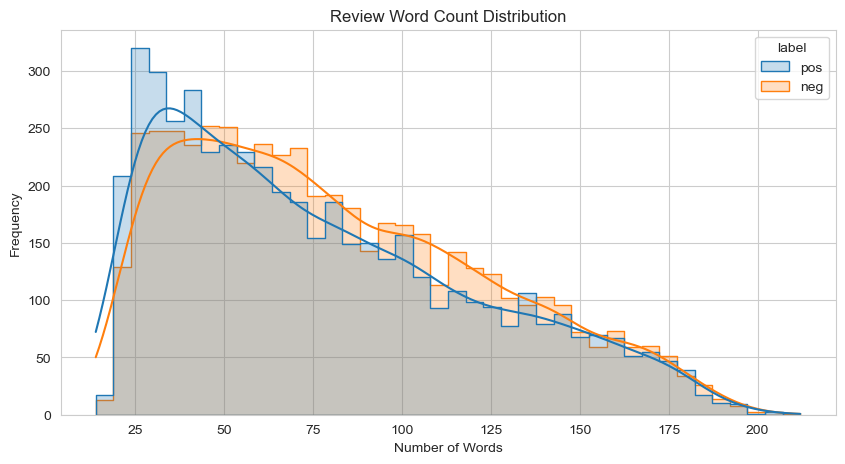

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="label",
    bins=40,
    kde=True,
    element="step"
)

plt.title("Review Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

Step 14: Box plot of review length

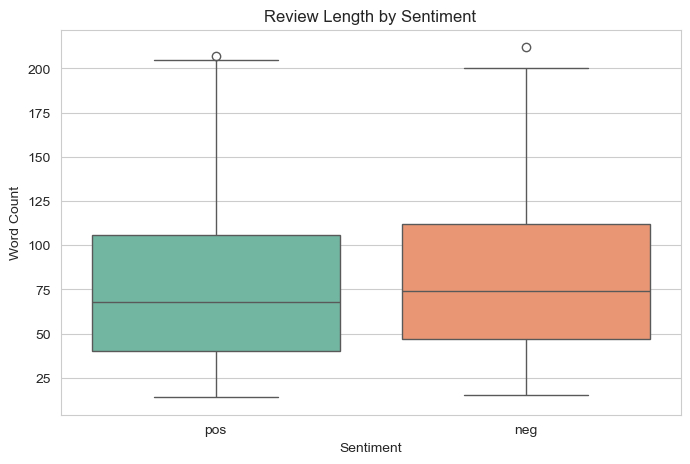

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="label",
    y="word_count",
    hue="label",
    palette="Set2",
    legend=False
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")

plt.show()

Step 15: Create text preprocessing function

In [15]:
# Preserve negation words because they are important for sentiment.
custom_stopwords = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "nor", "never"
}

def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove numbers
    text = re.sub(r"\d+", " ", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stopwords while preserving negations
    words = text.split()

    words = [
        word for word in words
        if word not in custom_stopwords
    ]

    return " ".join(words)


print("Text preprocessing function created successfully!")

Text preprocessing function created successfully!


In [16]:
# Create cleaned review column
df["cleaned_review"] = df["review"].apply(clean_text)

# Display original and cleaned reviews
display(df[["review", "cleaned_review", "label"]].head(10))

,review,cleaned_review,label
0,Stuning even for the non-gamer: This sound tra...,stuning non gamer sound track beautiful paints...,pos
1,The best soundtrack ever to anything.: I'm rea...,best soundtrack m reading lot reviews saying b...,pos
2,Amazing!: This soundtrack is my favorite music...,amazing soundtrack favorite music time hands i...,pos
3,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack truly like soundtrack enj...,pos
4,"Remember, Pull Your Jaw Off The Floor After He...",remember pull jaw floor hearing ve played game...,pos
5,an absolute masterpiece: I am quite sure any o...,absolute masterpiece quite sure actually takin...,pos
6,"Buyer beware: This is a self-published book, a...",buyer beware self published book want know rea...,neg
7,Glorious story: I loved Whisper of the wicked ...,glorious story loved whisper wicked saints sto...,pos
8,A FIVE STAR BOOK: I just finished reading Whis...,star book just finished reading whisper wicked...,pos
9,Whispers of the Wicked Saints: This was a easy...,whispers wicked saints easy read book want rea...,pos


Step 17: Check cleaned data

In [17]:
# Check empty cleaned reviews
print("Empty Cleaned Reviews:",
      (df["cleaned_review"] == "").sum())

# Remove empty cleaned reviews
df = df[df["cleaned_review"] != ""]

# Reset index
df.reset_index(drop=True, inplace=True)

print("Final Dataset Shape:", df.shape)

Empty Cleaned Reviews: 0
Final Dataset Shape: (10000, 5)


Step 18: Generate positive word cloud

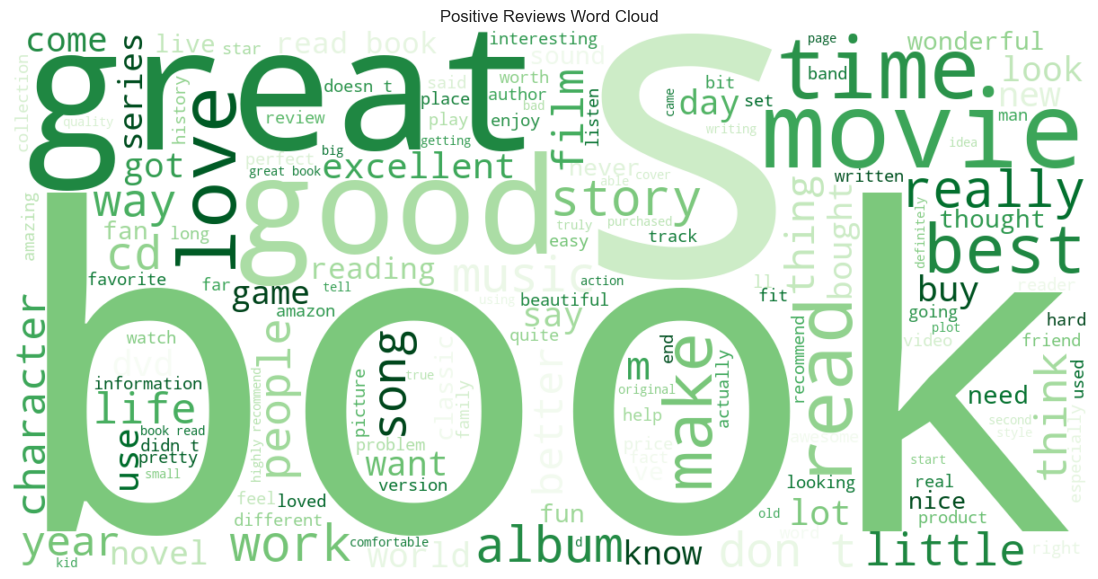

In [18]:
positive_text = " ".join(
    df[df["label"] == "pos"]["cleaned_review"]
)

positive_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    colormap="Greens"
).generate(positive_text)

plt.figure(figsize=(15, 7))

plt.imshow(positive_wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Positive Reviews Word Cloud")

plt.show()

Step 19: Generate negative word cloud

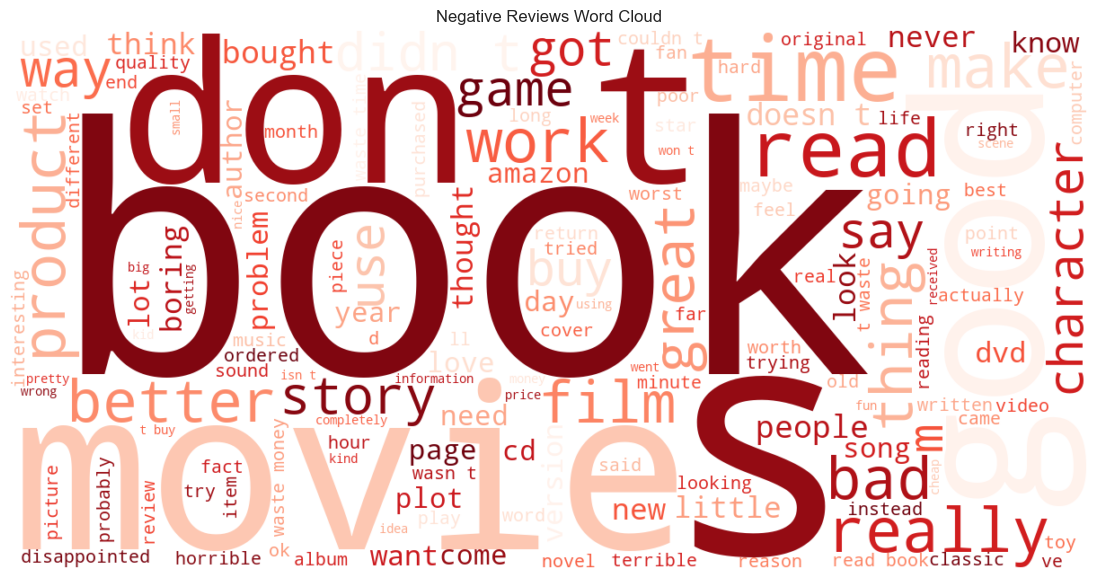

In [19]:
negative_text = " ".join(
    df[df["label"] == "neg"]["cleaned_review"]
)

negative_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    colormap="Reds"
).generate(negative_text)

plt.figure(figsize=(15, 7))

plt.imshow(negative_wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Negative Reviews Word Cloud")

plt.show()

Step 20: Find most common positive words

In [20]:
positive_words = positive_text.split()

positive_word_counts = Counter(positive_words)

top_positive_words = positive_word_counts.most_common(20)

positive_words_df = pd.DataFrame(
    top_positive_words,
    columns=["Word", "Frequency"]
)

display(positive_words_df)

,Word,Frequency
0,book,3390
1,s,3179
2,great,2135
3,not,1963
4,t,1871
5,good,1667
6,read,1605
7,like,1290
8,movie,1121
9,just,1036


Step 21: Visualize most common positive words

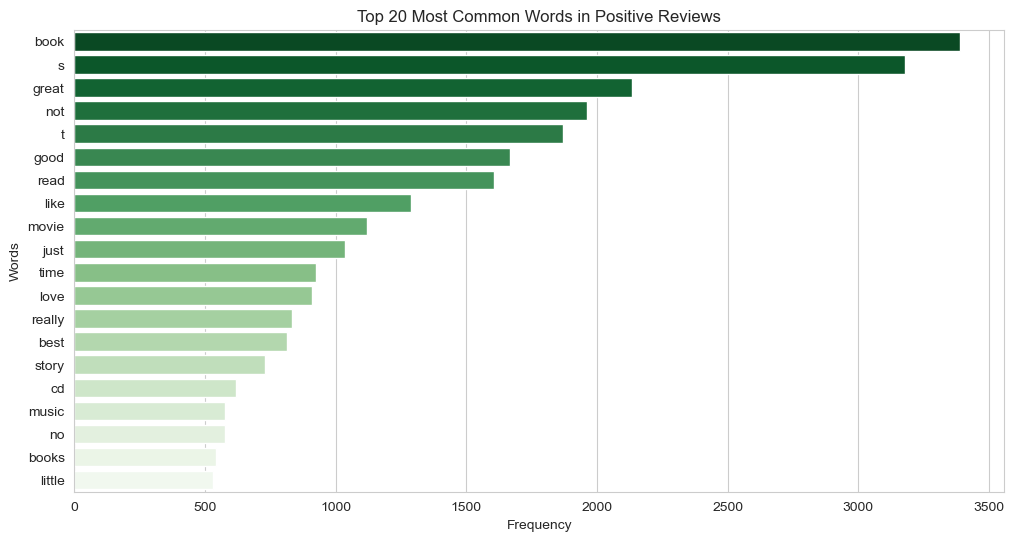

In [21]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=positive_words_df,
    x="Frequency",
    y="Word",
    hue="Word",
    palette="Greens_r",
    legend=False
)

plt.title("Top 20 Most Common Words in Positive Reviews")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

Step 22: Find most common negative words

In [22]:
negative_words = negative_text.split()

negative_word_counts = Counter(negative_words)

top_negative_words = negative_word_counts.most_common(20)

negative_words_df = pd.DataFrame(
    top_negative_words,
    columns=["Word", "Frequency"]
)

display(negative_words_df)

,Word,Frequency
0,not,4449
1,t,3599
2,book,3277
3,s,2919
4,like,1569
5,just,1526
6,movie,1519
7,no,1258
8,read,1222
9,good,1160


Step 23: Visualize most common negative words

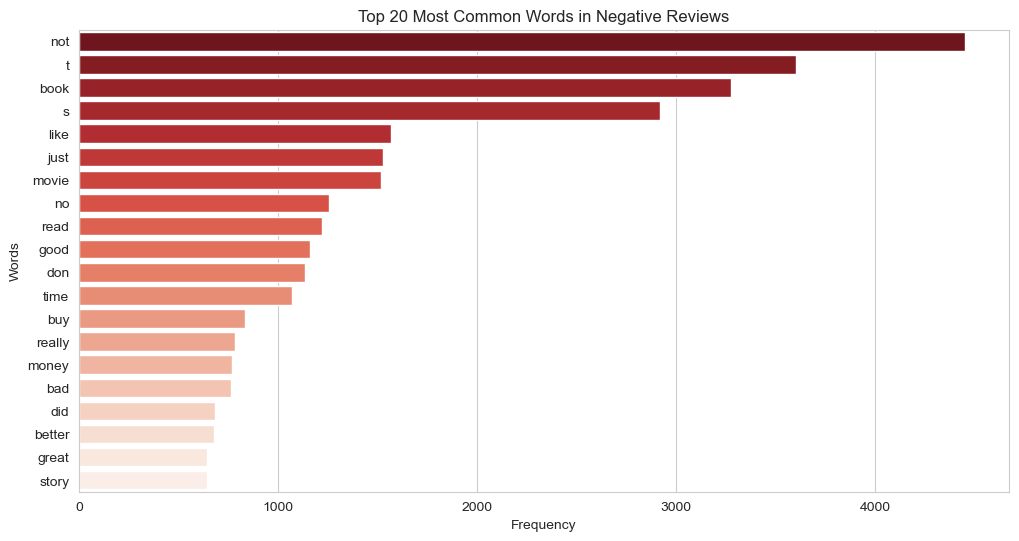

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=negative_words_df,
    x="Frequency",
    y="Word",
    hue="Word",
    palette="Reds_r",
    legend=False
)

plt.title("Top 20 Most Common Words in Negative Reviews")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

Step 24: Prepare independent and dependent variables

In [24]:
# Independent variable
X = df["cleaned_review"]

# Dependent variable
y = df["label"]

print("Independent Variable Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

Independent Variable Shape: (10000,)
Dependent Variable Shape: (10000,)


Step 25: Split dataset into training and testing

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Sentiment Distribution:")
print(y_train.value_counts())

print("\nTesting Sentiment Distribution:")
print(y_test.value_counts())

Training Data: (8000,)
Testing Data: (2000,)

Training Sentiment Distribution:
label
neg    4078
pos    3922
Name: count, dtype: int64

Testing Sentiment Distribution:
label
neg    1019
pos     981
Name: count, dtype: int64


Step 26: Convert text into TF-IDF features

In [26]:
# TF-IDF feature extraction
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (8000, 10000)
Testing TF-IDF Shape: (2000, 10000)


Step 27: Train Logistic Regression model

In [27]:
# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Predict testing data
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [28]:
lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_precision = precision_score(
    y_test,
    lr_predictions,
    pos_label="neg"
)

lr_recall = recall_score(
    y_test,
    lr_predictions,
    pos_label="neg"
)

lr_f1 = f1_score(
    y_test,
    lr_predictions,
    pos_label="neg"
)

print("Logistic Regression Results")
print("--------------------------------")

print("Accuracy:", lr_accuracy)
print("Negative Precision:", lr_precision)
print("Negative Recall:", lr_recall)
print("Negative F1 Score:", lr_f1)

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Results
--------------------------------
Accuracy: 0.8645
Negative Precision: 0.8638132295719845
Negative Recall: 0.8714425907752699
Negative F1 Score: 0.8676111382510991

Classification Report:
              precision    recall  f1-score   support

         neg       0.86      0.87      0.87      1019
         pos       0.87      0.86      0.86       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



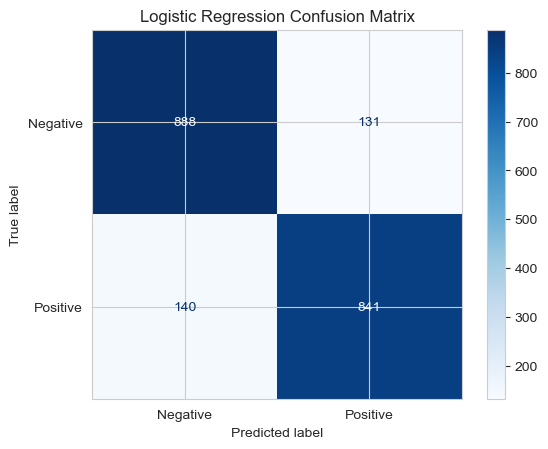

In [29]:
lr_cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=["neg", "pos"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

Step 30: Train Multinomial Naive Bayes

In [31]:
# Initialize Naive Bayes
nb_model = MultinomialNB()

# Train model
nb_model.fit(X_train_tfidf, y_train)

# Predict testing data
nb_predictions = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes Model Trained Successfully!")

Multinomial Naive Bayes Model Trained Successfully!


In [32]:
nb_accuracy = accuracy_score(y_test, nb_predictions)

nb_precision = precision_score(
    y_test,
    nb_predictions,
    pos_label="neg"
)

nb_recall = recall_score(
    y_test,
    nb_predictions,
    pos_label="neg"
)

nb_f1 = f1_score(
    y_test,
    nb_predictions,
    pos_label="neg"
)

print("Multinomial Naive Bayes Results")
print("--------------------------------")

print("Accuracy:", nb_accuracy)
print("Negative Precision:", nb_precision)
print("Negative Recall:", nb_recall)
print("Negative F1 Score:", nb_f1)

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

Multinomial Naive Bayes Results
--------------------------------
Accuracy: 0.846
Negative Precision: 0.8428158148505304
Negative Recall: 0.8577036310107949
Negative F1 Score: 0.8501945525291829

Classification Report:
              precision    recall  f1-score   support

         neg       0.84      0.86      0.85      1019
         pos       0.85      0.83      0.84       981

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000



Step 32: Train Linear SVM

In [33]:
# Initialize Linear SVM
svm_model = LinearSVC(
    random_state=42,
    max_iter=5000
)

# Train model
svm_model.fit(X_train_tfidf, y_train)

# Predict testing data
svm_predictions = svm_model.predict(X_test_tfidf)

print("Linear SVM Model Trained Successfully!")

Linear SVM Model Trained Successfully!


In [34]:
svm_accuracy = accuracy_score(y_test, svm_predictions)

svm_precision = precision_score(
    y_test,
    svm_predictions,
    pos_label="neg"
)

svm_recall = recall_score(
    y_test,
    svm_predictions,
    pos_label="neg"
)

svm_f1 = f1_score(
    y_test,
    svm_predictions,
    pos_label="neg"
)

print("Linear SVM Results")
print("--------------------------------")

print("Accuracy:", svm_accuracy)
print("Negative Precision:", svm_precision)
print("Negative Recall:", svm_recall)
print("Negative F1 Score:", svm_f1)

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

Linear SVM Results
--------------------------------
Accuracy: 0.861
Negative Precision: 0.8600583090379009
Negative Recall: 0.8684985279685966
Negative F1 Score: 0.8642578125

Classification Report:
              precision    recall  f1-score   support

         neg       0.86      0.87      0.86      1019
         pos       0.86      0.85      0.86       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



Step 34: Compare all machine learning models

In [35]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Linear SVM"
    ],

    "Accuracy": [
        lr_accuracy,
        nb_accuracy,
        svm_accuracy
    ],

    "Negative Precision": [
        lr_precision,
        nb_precision,
        svm_precision
    ],

    "Negative Recall": [
        lr_recall,
        nb_recall,
        svm_recall
    ],

    "Negative F1 Score": [
        lr_f1,
        nb_f1,
        svm_f1
    ]
})

display(
    model_comparison.sort_values(
        by="Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Negative Precision,Negative Recall,Negative F1 Score
0,Logistic Regression,0.8645,0.863813,0.871443,0.867611
2,Linear SVM,0.8610,0.860058,0.868499,0.864258
1,Multinomial Naive Bayes,0.8460,0.842816,0.857704,0.850195


Step 35: Visualize model accuracy comparison

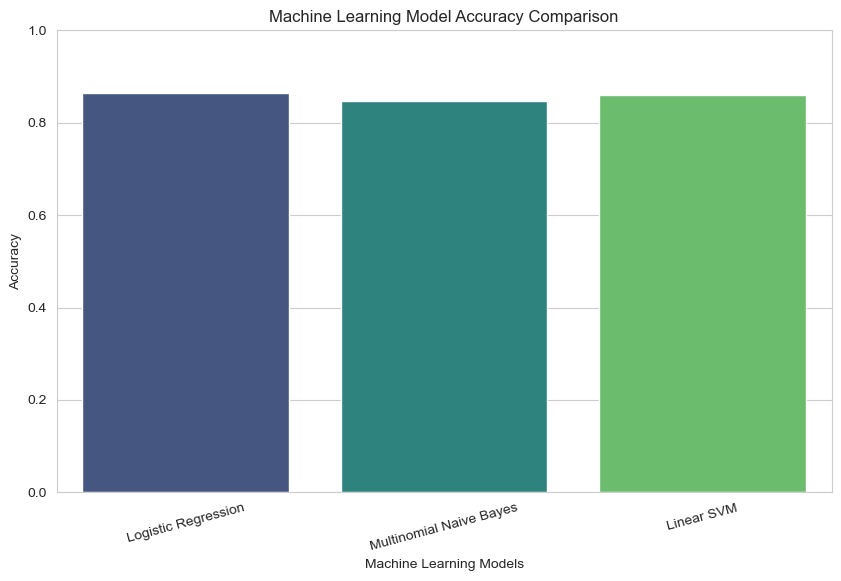

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

Step 36: Visualize F1-score comparison

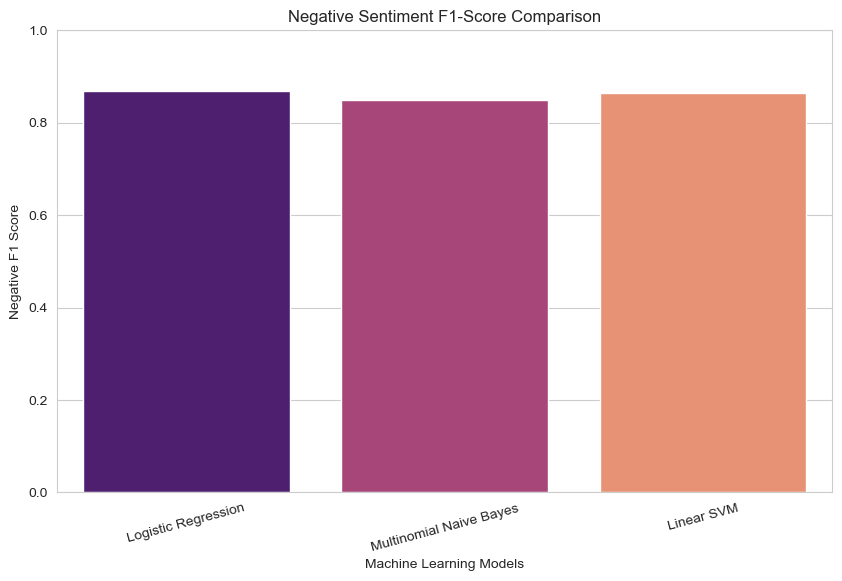

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Negative F1 Score",
    hue="Model",
    palette="magma",
    legend=False
)

plt.title("Negative Sentiment F1-Score Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Negative F1 Score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

Step 37: Perform 5-fold cross-validation

In [38]:
# Create a pipeline to prevent TF-IDF leakage across CV folds
cv_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Stratified 5-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=[
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ],
    return_train_score=True
)

print("Cross Validation Results")
print("--------------------------------")

for metric in [
    "test_accuracy",
    "test_precision_macro",
    "test_recall_macro",
    "test_f1_macro"
]:

    print(
        metric,
        ":",
        round(cv_results[metric].mean(), 4)
    )

Cross Validation Results
--------------------------------
test_accuracy : 0.868
test_precision_macro : 0.868
test_recall_macro : 0.868
test_f1_macro : 0.868


Step 38: Hyperparameter tuning using GridSearchCV

In [39]:
# Pipeline for hyperparameter tuning
tuning_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Parameter grid
param_grid = {
    "tfidf__max_features": [5000, 10000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "model__C": [0.1, 1, 10]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

# Train grid search
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation F1 Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters:
{'model__C': 1, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}

Best Cross Validation F1 Score:
0.8663159926431228


Step 39: Evaluate tuned model

In [40]:
# Best trained model
best_model = grid_search.best_estimator_

# Predictions
tuned_predictions = best_model.predict(X_test)

# Evaluation
print("Tuned Logistic Regression Results")
print("--------------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, tuned_predictions)
)

print(
    "\nClassification Report:"
)

print(
    classification_report(
        y_test,
        tuned_predictions
    )
)

Tuned Logistic Regression Results
--------------------------------
Accuracy: 0.8585

Classification Report:
              precision    recall  f1-score   support

         neg       0.86      0.87      0.86      1019
         pos       0.86      0.85      0.85       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



Step 40: Compare baseline and improved model

In [41]:
# Historical baseline result from the original implementation
baseline_accuracy = 0.843

# Tuned model accuracy
tuned_accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

baseline_comparison = pd.DataFrame({
    "Model": [
        "Original Baseline",
        "Tuned Logistic Regression"
    ],

    "Accuracy": [
        baseline_accuracy,
        tuned_accuracy
    ]
})

display(baseline_comparison)

,Model,Accuracy
0,Original Baseline,0.8430
1,Tuned Logistic Regression,0.8585


Step 41: Baseline comparison visualization

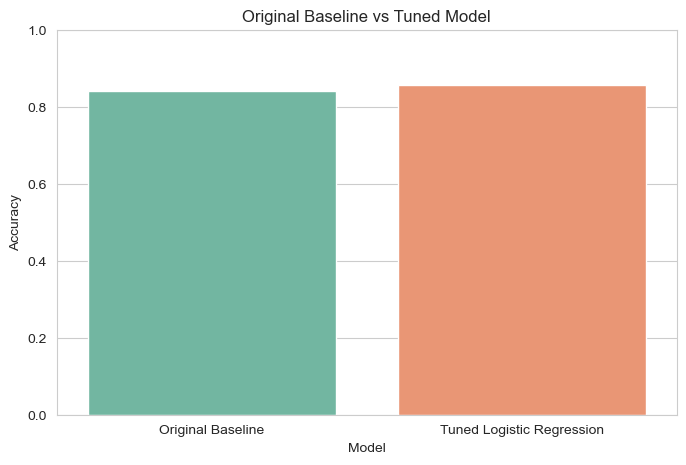

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=baseline_comparison,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Original Baseline vs Tuned Model")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.show()

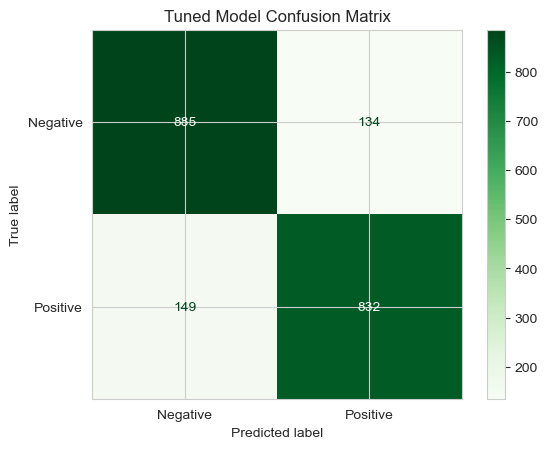

In [43]:
tuned_cm = confusion_matrix(
    y_test,
    tuned_predictions,
    labels=["neg", "pos"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=tuned_cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Greens")

plt.title("Tuned Model Confusion Matrix")

plt.show()

Step 43: ROC-AUC evaluation

ROC-AUC Score: 0.9303118425751695


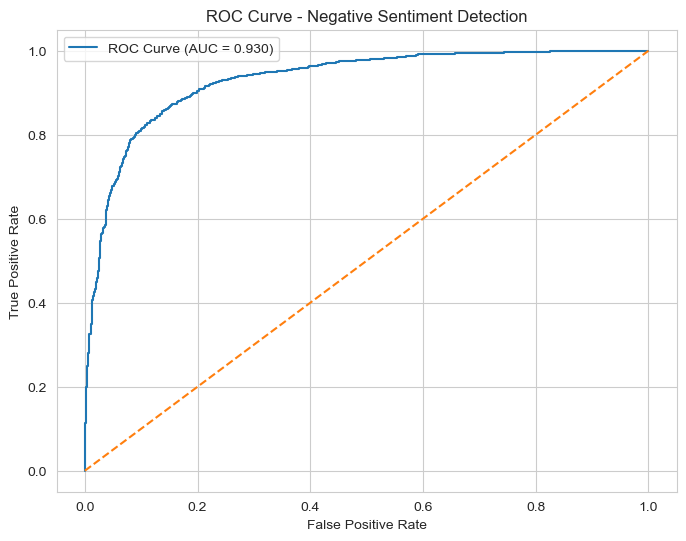

In [44]:
# Probability of negative sentiment
negative_class_index = list(
    best_model.classes_
).index("neg")

negative_probabilities = best_model.predict_proba(
    X_test
)[:, negative_class_index]

# Convert labels into binary values
y_test_binary = (
    y_test == "neg"
).astype(int)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_test_binary,
    negative_probabilities
)

print("ROC-AUC Score:", roc_auc)

# ROC Curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    negative_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Negative Sentiment Detection")

plt.legend()

plt.show()

Step 44: Precision-Recall curve

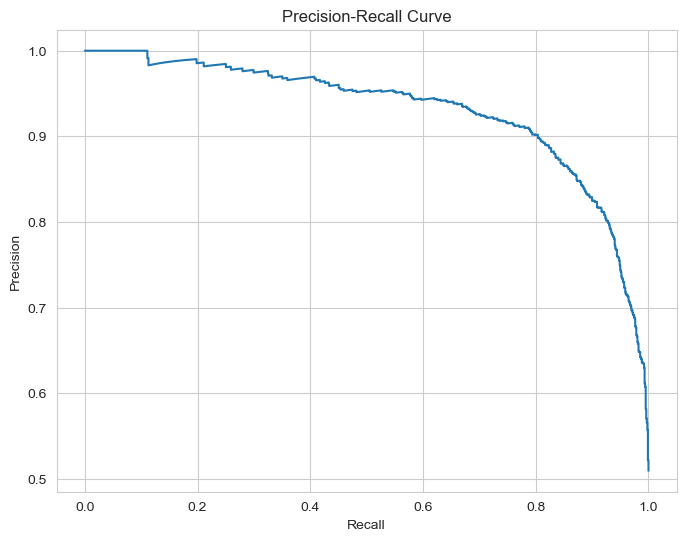

In [45]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_test_binary,
        negative_probabilities
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.show()

Step 45: Analyze incorrect predictions

In [46]:
# Create prediction analysis dataframe
error_analysis = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": tuned_predictions,
    "Review": X_test.values
})

# Filter incorrect predictions
incorrect_predictions = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print(
    "Total Incorrect Predictions:",
    len(incorrect_predictions)
)

display(
    incorrect_predictions.head(20)
)

Total Incorrect Predictions: 283


,Actual,Predicted,Review
7,pos,neg,interesting fascinating read does not focus mo...
10,neg,pos,second time sandisk e series second sansa e se...
15,pos,neg,creepy huge fan original just waiting hate fil...
26,pos,neg,works does advertised bought current reviews s...
27,neg,pos,favorite toys blue eyes shining dragon awesome...
36,neg,pos,s laughing husband expecting baby day opted ch...
61,pos,neg,king sleeze s enjoy bad scripts bad actors poo...
63,neg,pos,not spanish alguien puede decir porque la seri...
68,pos,neg,energizers icebreakers good h club using activ...
74,pos,neg,great story really enjoyed movie bringing baal...


Step 46: Analyze false negatives and false positives

In [47]:
# False negatives: actual negative, predicted positive
false_negatives = error_analysis[
    (error_analysis["Actual"] == "neg") &
    (error_analysis["Predicted"] == "pos")
]

# False positives: actual positive, predicted negative
false_positives = error_analysis[
    (error_analysis["Actual"] == "pos") &
    (error_analysis["Predicted"] == "neg")
]

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

print("\nFalse Negative Examples:")
display(false_negatives.head(5))

print("\nFalse Positive Examples:")
display(false_positives.head(5))

False Negatives: 134
False Positives: 149

False Negative Examples:


,Actual,Predicted,Review
10,neg,pos,second time sandisk e series second sansa e se...
27,neg,pos,favorite toys blue eyes shining dragon awesome...
36,neg,pos,s laughing husband expecting baby day opted ch...
63,neg,pos,not spanish alguien puede decir porque la seri...
85,neg,pos,don t listen absolutely awful watched christma...



False Positive Examples:


,Actual,Predicted,Review
7,pos,neg,interesting fascinating read does not focus mo...
15,pos,neg,creepy huge fan original just waiting hate fil...
26,pos,neg,works does advertised bought current reviews s...
61,pos,neg,king sleeze s enjoy bad scripts bad actors poo...
68,pos,neg,energizers icebreakers good h club using activ...


Step 47: Identify important positive and negative words

In [48]:
# Extract the trained Logistic Regression model
final_lr = best_model.named_steps["model"]

# Extract TF-IDF feature names
feature_names = best_model.named_steps[
    "tfidf"
].get_feature_names_out()

# Extract model coefficients
coefficients = final_lr.coef_[0]

# Find positive and negative class indexes
positive_index = list(final_lr.classes_).index("pos")
negative_index = list(final_lr.classes_).index("neg")

# Logistic Regression has one coefficient vector for binary classification.
# Positive coefficients indicate the second class in classes_.
if final_lr.classes_[1] == "pos":
    positive_coefficients = coefficients
else:
    positive_coefficients = -coefficients

# Top positive features
top_positive_indices = np.argsort(
    positive_coefficients
)[-20:][::-1]

# Top negative features
top_negative_indices = np.argsort(
    positive_coefficients
)[:20]

print("Important Positive Words:")

for index in top_positive_indices:
    print(
        feature_names[index],
        round(positive_coefficients[index], 4)
    )

print("\nImportant Negative Words:")

for index in top_negative_indices:
    print(
        feature_names[index],
        round(positive_coefficients[index], 4)
    )

Important Positive Words:
great 7.1503
excellent 4.6183
best 4.4238
love 4.3081
good 3.9501
perfect 3.5581
wonderful 3.0114
amazing 2.9889
easy 2.8775
favorite 2.7242
works 2.4526
loved 2.4343
fun 2.3666
awesome 2.3035
loves 2.2774
beautiful 2.1065
fantastic 2.0171
highly 2.0023
enjoyed 1.9983
pleased 1.9715

Important Negative Words:
not -7.2152
boring -4.9946
bad -4.4
worst -4.2725
poor -4.23
disappointed -3.9492
waste -3.9263
no -3.2792
money -3.2404
don -3.2273
disappointing -3.0925
horrible -2.8311
terrible -2.7978
didn -2.3885
not worth -2.3638
not good -2.2832
disappointment -2.2183
not recommend -2.1905
doesn -2.1795
return -2.1546


Step 48: Create a custom review prediction function

In [49]:
def predict_sentiment(review):

    # Predict using the complete trained pipeline
    prediction = best_model.predict([review])[0]

    # Predict class probabilities
    probabilities = best_model.predict_proba([review])[0]

    # Get class labels
    classes = best_model.classes_

    # Convert probabilities into dictionary
    probability_dict = dict(
        zip(classes, probabilities)
    )

    print("Review:", review)

    print("\nPredicted Sentiment:", prediction.upper())

    print(
        "Positive Probability:",
        round(probability_dict["pos"] * 100, 2),
        "%"
    )

    print(
        "Negative Probability:",
        round(probability_dict["neg"] * 100, 2),
        "%"
    )

    return prediction

Step 49: Test custom positive review

In [50]:
sample_positive_review = (
    "Excellent product. The quality is amazing "
    "and I absolutely love it."
)

predict_sentiment(sample_positive_review)

Review: Excellent product. The quality is amazing and I absolutely love it.

Predicted Sentiment: POS
Positive Probability: 97.03 %
Negative Probability: 2.97 %


'pos'

Step 50: Test custom negative review

In [51]:
sample_negative_review = (
    "Very poor quality. The product stopped working "
    "after two days. I am extremely disappointed."
)

predict_sentiment(sample_negative_review)

Review: Very poor quality. The product stopped working after two days. I am extremely disappointed.

Predicted Sentiment: NEG
Positive Probability: 2.71 %
Negative Probability: 97.29 %


'neg'

Step 51: Test mixed sentiment review

In [52]:
sample_mixed_review = (
    "The product looks good but the quality is poor "
    "and the battery does not last long."
)

predict_sentiment(sample_mixed_review)

Review: The product looks good but the quality is poor and the battery does not last long.

Predicted Sentiment: NEG
Positive Probability: 10.88 %
Negative Probability: 89.12 %


'neg'

Step 52: Save the final trained model

In [53]:
# Save complete pipeline including TF-IDF and Logistic Regression
joblib.dump(
    best_model,
    "amazon_sentiment_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Step 53: Load saved model

In [54]:
# Load saved model
loaded_model = joblib.load(
    "amazon_sentiment_model.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


Step 54: Test loaded model

In [55]:
test_review = (
    "Amazing product. Excellent quality and fast delivery."
)

loaded_prediction = loaded_model.predict(
    [test_review]
)

print("Review:", test_review)

print(
    "Predicted Sentiment:",
    loaded_prediction[0].upper()
)

Review: Amazing product. Excellent quality and fast delivery.
Predicted Sentiment: POS


Step 55: Generate final performance summary

In [56]:
final_accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

final_precision = precision_score(
    y_test,
    tuned_predictions,
    pos_label="neg"
)

final_recall = recall_score(
    y_test,
    tuned_predictions,
    pos_label="neg"
)

final_f1 = f1_score(
    y_test,
    tuned_predictions,
    pos_label="neg"
)

final_results = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Negative Precision",
        "Negative Recall",
        "Negative F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        roc_auc
    ]
})

display(final_results)

,Evaluation Metric,Score
0,Accuracy,0.858500
1,Negative Precision,0.855899
2,Negative Recall,0.868499
3,Negative F1 Score,0.862153
4,ROC-AUC,0.930312


Step 56: Export model comparison results

In [57]:
# Save model comparison
model_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

# Save final evaluation results
final_results.to_csv(
    "final_evaluation_results.csv",
    index=False
)

# Save incorrect predictions
incorrect_predictions.to_csv(
    "incorrect_predictions.csv",
    index=False
)

print("All result files exported successfully!")

All result files exported successfully!


Step 57: Final dataset export

In [58]:
# Export cleaned dataset
df.to_csv(
    "cleaned_amazon_reviews.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


Step 58: Final project completion

In [59]:
print("=" * 60)

print("TEXT CLASSIFICATION AND SENTIMENT ANALYSIS")

print("=" * 60)

print("Project: Amazon Customer Review Sentiment Analysis")

print("Total Reviews:", len(df))

print(
    "Positive Reviews:",
    (df["label"] == "pos").sum()
)

print(
    "Negative Reviews:",
    (df["label"] == "neg").sum()
)

print("Best Model: Tuned Logistic Regression")

print(
    "Final Test Accuracy:",
    round(final_accuracy * 100, 2),
    "%"
)

print(
    "Negative Sentiment F1 Score:",
    round(final_f1, 4)
)

print("Model File: amazon_sentiment_model.pkl")

print("=" * 60)

print("PROJECT EXECUTION COMPLETED SUCCESSFULLY!")

TEXT CLASSIFICATION AND SENTIMENT ANALYSIS
Project: Amazon Customer Review Sentiment Analysis
Total Reviews: 10000
Positive Reviews: 4903
Negative Reviews: 5097
Best Model: Tuned Logistic Regression
Final Test Accuracy: 85.85 %
Negative Sentiment F1 Score: 0.8622
Model File: amazon_sentiment_model.pkl
PROJECT EXECUTION COMPLETED SUCCESSFULLY!
